In [45]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [46]:
# FOR CONVERSION OF HSRS DATAFRAME
# path = r"/Users/jorgevillazon/Library/CloudStorage/OneDrive-UCSanDiego/integrated_pipeline_backup/HSI_data/CODEX_clusters_masks_output_csv/masked_predictions_percentages.csv"
# hsi_pred_csv = pd.read_csv(path)
# index_cols = ['Image_Name', 'Unit', 'Instance_Label', 'Source_ID']
# percentages_wide_df = hsi_pred_csv.pivot(index=index_cols, columns='Molecule', values='Percentage').reset_index()

# unit_clusters = {
#     "Cluster1": "Glomeruli | Podo, CD31",
#     "Cluster2": "PT | LRP2",
#     "Cluster3": "PT | LRP2, AQP1, CD90",
#     "Cluster4": "PT | THY1",
#     "Cluster5": "PT | PROM1/VCAM1",
#     "Cluster6": "TDL | AQP1, Cyto8 (N1)",
#     "Cluster7": "TDL | AQP1, Cyto8 (N2)",
#     "Cluster8": "TAL | NaK/UMOD",
#     "Cluster9": "TAL | UMOD",
#     "Cluster10": "TAL | UMOD",
#     "Cluster11": "DCT | SLC12a3",
#     "Cluster12": "DN | Cyto8",
#     "Cluster13": "DN | Cyto8",
#     "Cluster14": "DN | Cyto8",
#     "Cluster15": "DN | Cyto8, Bcat",
#     "Cluster16": "DN | Cyto8, Bcat, Ecad",
#     "Cluster17": "DN | Cyto8, Ecad",
#     "Cluster18": "Endothelium | CD31",
#     "Cluster19": "Endothelium | CD31, Podo",
#     "Cluster20": "Pericytes | CD90, CD31(-)",
#     "Cluster21": "VSMCs | aSMA",
#     "Cluster22": "Immune | CD20",
#     "Cluster23": "Immune - MP | CD45, CD206",
#     "Cluster24": "Immune - T | CD3, CD4",
#     "Cluster25": "Immune - T | CD3, CD8",
#     "Cluster26": "Interstitial cells | IGFBP7"
# }

# percentages_wide_df = percentages_wide_df.rename(columns={'Unit': 'mask_name', 'Source_ID':'tissue_id'})
# percentages_wide_df['unit'] = percentages_wide_df['mask_name'].map(unit_clusters)
# percentages_wide_df.drop(columns='Instance_Label', inplace=True)
# percentages_wide_df.to_csv(r"/Users/jorgevillazon/Library/CloudStorage/OneDrive-UCSanDiego/integrated_pipeline_backup/HSI_data/CODEX_clusters_masks_output_csv/percentages-output.csv", index=False)


In [47]:
fib_path = r"/Users/jorgevillazon/Library/CloudStorage/OneDrive-UCSanDiego/integrated_pipeline/WSI_data/WSI_data/fib-output.csv"
fib_df = pd.read_csv(fib_path)
fib_df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/Users/jorgevillazon/Library/CloudStorage/OneDrive-UCSanDiego/integrated_pipeline/WSI_data/WSI_data/fib-output.csv'

In [ ]:
df.shape

In [ ]:
path = r"/Users/jorgevillazon/Library/CloudStorage/OneDrive-UCSanDiego/integrated_pipeline/WSI_data/WSI_data/CODEX_clusters-regions_masks_output_csv-test/output.csv"
df = pd.read_csv(path)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

filter_cluster = [
    "Cluster1",
    "Cluster2",
    #   "Cluster3",
    "Cluster4",
    "Cluster5",
    "Cluster6",
    # "Cluster7",
    "Cluster8",
    "Cluster9",
    #   "Cluster10",
    "Cluster11",
    "Cluster12",
    #   "Cluster13",
    #   "Cluster14",
    "Cluster15",
    "Cluster16",
    "Cluster17",
    "Cluster18",
    "Cluster19",
    "Cluster20",
    "Cluster21",
    "Cluster22",
    "Cluster23",
    "Cluster24",
    "Cluster25",
    "Cluster26"
    ]

group_order = [
    'Outer Cortex', 
    'Inner Cortex', 
    'Outer Stripe', 
    'Inner Stripe', 
    'Inner Medulla'
    ]

unit_clusters = {
"Cluster1": "Glomeruli | Podo, CD31",
"Cluster2": "PT | LRP2",
"Cluster3": "PT | LRP2, AQP1, CD90",
"Cluster4": "PT | THY1",
"Cluster5": "PT | PROM1/VCAM1",
"Cluster6": "TDL | AQP1, Cyto8 (N1)",
"Cluster7": "TDL | AQP1, Cyto8 (N2)",
"Cluster8": "TAL | NaK/UMOD",
"Cluster9": "TAL | UMOD",
"Cluster10": "TAL | UMOD",
"Cluster11": "DCT | SLC12a3",
"Cluster12": "DN | Cyto8",
"Cluster13": "DN | Cyto8",
"Cluster14": "DN | Cyto8",
"Cluster15": "DN | Cyto8, Bcat",
"Cluster16": "DN | Cyto8, Bcat, Ecad",
"Cluster17": "DN | Cyto8, Ecad",
"Cluster18": "Endothelium | CD31",
"Cluster19": "Endothelium | CD31, Podo",
"Cluster20": "Pericytes | CD90, CD31(-)",
"Cluster21": "VSMCs | aSMA",
"Cluster22": "Immune | CD20",
"Cluster23": "Immune - MP | CD45, CD206",
"Cluster24": "Immune - T | CD3, CD4",
"Cluster25": "Immune - T | CD3, CD8",
"Cluster26": "Interstitial cells | IGFBP7"
}

df = df.replace({
    'Middle Cortex': 'Outer Cortex', 
    'Juxtamedullary Cortex': 'Inner Cortex', 
    'Cluster3':'Cluster4',
    unit_clusters.get('Cluster3') : unit_clusters.get('Cluster4'),
    'Cluster13': 'Cluster12', 
    unit_clusters.get('Cluster13') : unit_clusters.get('Cluster12'),
    'Cluster14': 'Cluster12', 
    unit_clusters.get('Cluster14') : unit_clusters.get('Cluster12'),
    'Cluster10': 'Cluster9', 
    unit_clusters.get('Cluster10') : unit_clusters.get('Cluster9'),
    'Cluster7':'Cluster6',
    unit_clusters.get('Cluster7') : 'TDL | AQP1, Cyto8',
    unit_clusters.get('Cluster6') : 'TDL | AQP1, Cyto8',
    } 
)
if 'group' in df.columns and not df['group'].isna().all():
    df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)
    if "Inner Cortex" in df['group'].unique():
        unit_size = df.groupby('mask_name')['mask_name'].transform('count')
        unit_group_size = df.groupby(['group', 'mask_name'])['mask_name'].transform('count')
        df['Percentage'] = (unit_group_size / unit_size) * 100

        df = df[df['Percentage'] >= 7].copy()
        df = df.drop(columns=['Percentage'])

value_cols = df.select_dtypes(include='number').columns.tolist()
value_cols = [val_col for val_col in value_cols if 'centroid' not in val_col]

df = df[(df[value_cols] != 0).all(axis=1)].copy()
df[value_cols] = df.groupby(['tissue_id'])[value_cols].transform(lambda x: (x - x.mean()) / (x.std() + 1e-8))

        
# for i, val_col in enumerate(value_cols):
#     df[val_col] = df[val_col].fillna(df.groupby(['group', 'mask_name', 'tissue_id'])[val_col].transform('median'))
if 'group' in df.columns:
    if set(['Outer Cortex', 'Inner Cortex', 'Outer Stripe', 'Inner Stripe', 'Inner Medulla']) & set(list(df['group'].unique())):    
        condition_tdl = (df['mask_name'].isin(['Cluster6', 'Cluster7']) & df['group'].isin(['Outer Cortex', 'Inner Cortex']))
        df.loc[condition_tdl, 'group'] = 'Outer Stripe'

        condition_pt = (df['mask_name'].isin(['Cluster2', 'Cluster4', 'Cluster5']) & df['group'].isin(['Inner Stripe']))
        df.loc[condition_pt, 'group'] = 'Outer Stripe'

        condition_tal = (df['mask_name'].isin(['Cluster8', 'Cluster9']) & df['group'].isin(['Inner Medulla']))
        df.loc[condition_tal, 'group'] = 'Inner Stripe'

        condition_glom = (df['mask_name'].isin(['Cluster1']) & df['group'].isin(['Outer Stripe']))
        df.loc[condition_glom, 'group'] = 'Inner Cortex'


cluster_colors= {
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    "Cluster3": "#10c922",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster8": "#840a62",
    "Cluster9": "#f47ad2",
    "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster12": "#0a3b84",
    "Cluster13": "#0e52b7",
    "Cluster14": "#0e52b7",
    "Cluster15": "#1369eb",
    "Cluster16": "#478af0",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster22": "#8b3103",
    "Cluster23": "#d44a05",
    "Cluster24": "#f9702a",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
}


unit_clusters = {
    "Cluster1": "Glomeruli | Podo, CD31",
    "Cluster2": "PT | LRP2",
    "Cluster3": "PT | LRP2, AQP1, CD90",
    "Cluster4": "PT | THY1",
    "Cluster5": "PT | PROM1/VCAM1",
    "Cluster6": "TDL | AQP1, Cyto8",
    "Cluster7": "TDL | AQP1, Cyto8",
    "Cluster8": "TAL | NaK/UMOD",
    "Cluster9": "TAL | UMOD",
    "Cluster10": "TAL | UMOD",
    "Cluster11": "DCT | SLC12a3",
    "Cluster12": "DN | Cyto8",
    "Cluster13": "DN | Cyto8",
    "Cluster14": "DN | Cyto8",
    "Cluster15": "DN | Cyto8, Bcat",
    "Cluster16": "DN | Cyto8, Bcat, Ecad",
    "Cluster17": "DN | Cyto8, Ecad",
    "Cluster18": "Endothelium | CD31",
    "Cluster19": "Endothelium | CD31, Podo",
    "Cluster20": "Pericytes | CD90, CD31(-)",
    "Cluster21": "VSMCs | aSMA",
    "Cluster22": "Immune | CD20",
    "Cluster23": "Immune - MP | CD45, CD206",
    "Cluster24": "Immune - T | CD3, CD4",
    "Cluster25": "Immune - T | CD3, CD8",
    "Cluster26": "Interstitial cells | IGFBP7"
}

ftu_map = {
    "Cluster1": "GL",
    "Cluster2": "PT",
    "Cluster3": "PT",
    "Cluster4": "PT",
    "Cluster5": "PT",
    "Cluster6": "TDL",
    "Cluster7": "TDL",
    "Cluster8": "TAL",
    "Cluster9": "TAL",
    "Cluster10": "TAL",
    "Cluster11": "DCT",
    "Cluster12": "DN",
    "Cluster13": "DN",
    "Cluster14": "DN",
    "Cluster15": "DN",
    "Cluster16": "DN",
    "Cluster17": "DN",
    "Cluster18": "Endo",
    "Cluster19": "Endo",
    "Cluster20": "Pericytes",
    "Cluster21": "VSMCs",
    "Cluster22": "Immune",
    "Cluster23": "MP",
    "Cluster24": "T",
    "Cluster25": "T",
    "Cluster26": "Interstitial"
}

df['FTU'] = df['mask_name'].map(ftu_map)

/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_46454/2356986907.py:92: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unit_group_size = df.groupby(['group', 'mask_name'])['mask_name'].transform('count')


In [ ]:
from pathlib import Path
col_groups = {
    "ORR": ["Redox"],
    "CAR" :[
        "CAR 18:2 (+H)",
        "CAR 18:1 (+H)",
        "CAR 18:0 (+H)"
    ],
    "CL" : [
        "CL 72:8 (-H)", #1447.965 CL 72:8 (-H),
        "CL 74:11 (-H)",# 1469.9493 CL 74:11 (-H)
    ],
    "LPL" : [
        "LPC 16:0 (+H)",
        "LPE 18:0 (-H)",
        "LPI 18:0 (-H)",
    ],
    "PL (Sat)" :[
        "PC 32:0 (+H)",
        "PE 16:0_18:0 (-H)",
        "PI 16:0_18:0 (-H)",
    ],
    "PL (MUFA)":[
        "PC 16:0_18:1 (+H)",
        "PC 18:0_18:1 (+H)",
        "PA 36:1 (-H)",
        "PS 18:0_18:1 (-H)",
        "PI 34:1 (-H)",
        "PI 18:0_18:1 (-H)",   
    ] ,
    "PL (AA)":[
        "PE 16:0_20:4 (-H)",
        "PE 18:1_20:4 (-H)",
        "PE 18:1_20:3 (-H)",
        "PS 16:0_20:4 (-H)",
        "PS 18:0_20:4 (-H)",
        "PI 16:0_20:4 (-H)",
        "PI 18:1_20:3 (-H)",
        "PC 35:4 (+H)",
        "PC 36:5 (+H)",
        "PC 18:0_20:4 (+H)",
    ],
    "PL (DHA)":[
        "PE 16:0_22:6 (-H)",
        "PG 18:1_22:6 (-H)",
    ],
    "PL (PUFA)":[
        "PC O-38:5 (+H)",
        "PC 38:5 (+H)",
        "PC 46:9 (-CH3)",
        "PE 49:9 (-H)",
        "PC 48:9 (-CH3)",
    ],

    "SM":[
        "SM 34:1;2O (+H)",
        "SM 38:1;20 (+H)",
        "SM 42:2;2O (+H)",
        "SM 42:1;2O (+H)",
        "SM 41:0;3O (+H)",
        "SM 42:0;3O (+H)",
        "SM 18:1;2O/16:0 (-CH3)"
    ],
    "SHexCer" : [
        "SHexCer 40:1;3O (-H)",
        "SHexCer 41:1;3O (-H)",
        "SHexCer 42:2;3O (-H)",
        "SHexCer 42:1;3O (-H)",
        "SHexCer 42:0;3O (-H)",
        "SHexCer 50:0;2O (-H)"
    ],
        "Lipid Unsat.": ["Lipid_Unsaturation"],
        "Lipid/Protein" : ["Lipid_to_Protein"],

    "Fib. Collagen": [
        # 'Collagen',
        "Collagen_Thickness",
        "Collagen_Coherence"
    ],

}
if 'Unnamed: 0' in fib_df.columns:
    fib_df = fib_df.drop(columns=['Unnamed: 0'])

for new_col, source_cols in col_groups.items():
    fib_df[new_col] = fib_df[source_cols].mean(axis=1)

filter_cluster = [
    # "Cluster1",
    # "Cluster2",
    # #   "Cluster3",
    # "Cluster4",
    # "Cluster5",
    # "Cluster6",
    # "Cluster7",
    # "Cluster8",
    # "Cluster9",
    # #   "Cluster10",
    # "Cluster11",
    # "Cluster12",
    # #   "Cluster13",
    # #   "Cluster14",
    # "Cluster15",
    # "Cluster16",
    # "Cluster17",
    "Cluster18",
    "Cluster19",
    "Cluster20",
    "Cluster21",
    "Cluster22",
    "Cluster23",
    "Cluster24",
    "Cluster25",
    "Cluster26"
    ]
# group_order = ['OC', 'IC', 'CM', 'OS', "IS"]
group_order = [
    "CFIB",
    "CMFIB",
    "IMFIB",
    "OMFIB",
    "pvFIB",
    # "IMpvFIB",
    "dFIB",
    "dIMFIB",
    "dOMFIB",
    "CMYOF",
    # "CMMYOF",
    "pvMYOF",
    "IMpvMYOF",
]
# group_order = ['Outer Cortex', 'Inner Cortex', 'Outer Stripe', 'Inner Stripe', 'Inner Medulla']

fib_df['group'] = fib_df['group'].replace({"CMMYOF": "CMYOF", "IMpvFIB": "IMpvMYOF"})
# fib_df = fib_df.replace({'Middle Cortex': 'Outer Cortex', 'Juxtamedullary Cortex': 'Inner Cortex', 'Cluster3':'Cluster4', 'Cluster13': 'Cluster12', 'Cluster14': 'Cluster12', 'Cluster10': 'Cluster9'} )

# group_map ={
#     'C1': 'Outer Cortex',
#     'C2': 'Inner Cortex',
#     'C3': 'CM Boundary',
#     'CM': 'Outer Stripe',
#     'M': 'Inner Stripe'
# }

unit_display_names = {
    "Cluster1": "Glomeruli | Podo, CD31",
    "Cluster2": "PT | LRP2",
    "Cluster3": "PT | LRP2, AQP1, CD90",
    "Cluster4": "PT | THY1",
    "Cluster5": "PT | PROM1/VCAM1",
    "Cluster6": "TDL | AQP1, Cyto8 (N1)",
    "Cluster7": "TDL | AQP1, Cyto8 (N2)",
    "Cluster8": "TAL | NaK/UMOD",
    "Cluster9": "TAL | UMOD",
    "Cluster10": "TAL | UMOD",
    "Cluster11": "DCT | SLC12a3",
    "Cluster12": "DN | Cyto8 (N1)",
    "Cluster13": "DN | Cyto8",
    "Cluster14": "DN | Cyto8 (N3)",
    "Cluster15": "DN | Cyto8, Bcat",
    "Cluster16": "DN | Cyto8, Bcat, Ecad",
    "Cluster17": "DN | Cyto8, Ecad",
    "Cluster18": "Endothelium | CD31",
    "Cluster19": "Endothelium | CD31, Podo",
    "Cluster20": "Pericytes | CD90, CD31(-)",
    "Cluster21": "VSMCs | aSMA",
    "Cluster22": "Immune | CD20",
    "Cluster23": "Immune - MP | CD45, CD206",
    "Cluster24": "Immune - T | CD3, CD4",
    "Cluster25": "Immune - T | CD3, CD8",
    "Cluster26": "Interstitial cells | IGFBP7"
}

# reversed_unit_map = {
#     v: k for k, v in unit_display_names.items()
# }

# fib_df['mask_name'] = fib_df['unit'].map(reversed_unit_map)
# fib_df['mask_name'] = pd.Categorical(fib_df['mask_name'], categories=filter_cluster, ordered=True)

if not fib_df['group'].isna().all():
    fib_df['group'] = pd.Categorical(fib_df['group'], categories=group_order, ordered=True)

for i, val_col in enumerate(fib_df.columns[7:]):
    fib_df[val_col] = fib_df[val_col].fillna(fib_df.groupby(['group', 'unit', 'tissue_id'])[val_col].transform('median'))

if set(['Outer Cortex', 'Inner Cortex', 'Outer Stripe', 'Inner Stripe', 'Inner Medulla']) & set(list(fib_df['group'].unique())):
    condition_tdl = (fib_df['mask_name'].isin(['Cluster6', 'Cluster7']) & fib_df['group'].isin(['Outer Cortex', 'Inner Cortex']))
    fib_df.loc[condition_tdl, 'group'] = 'Outer Stripe'

    condition_pt = (fib_df['mask_name'].isin(['Cluster2', 'Cluster4', 'Cluster5']) & fib_df['group'].isin(['Inner Stripe']))
    fib_df.loc[condition_pt, 'group'] = 'Outer Stripe'

    condition_tal = (fib_df['mask_name'].isin(['Cluster8', 'Cluster9']) & fib_df['group'].isin(['Inner Medulla']))
    fib_df.loc[condition_tal, 'group'] = 'Inner Stripe'

    condition_glom = (fib_df['mask_name'].isin(['Cluster1']) & fib_df['group'].isin(['Outer Stripe']))
    fib_df.loc[condition_glom, 'group'] = 'Inner Cortex'


# if not fib_df['group'].isna().all():
#     fib_df = fib_df[(fib_df.groupby(['mask_name', 'group'])['mask_name'].transform('size') / fib_df.groupby('group')['group'].transform('size')) * 100 >= 7]

items_list = list(fib_df.columns[7:])

unit_colors= {
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    "Cluster3": "#10c922",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster8": "#840a62",
    "Cluster9": "#f47ad2",
    "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster12": "#0a3b84",
    "Cluster13": "#0e52b7",
    "Cluster14": "#0e52b7",
    "Cluster15": "#1369eb",
    "Cluster16": "#478af0",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster22": "#8b3103",
    "Cluster23": "#d44a05",
    "Cluster24": "#f9702a",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
}

fib_df = fib_df[(fib_df[items_list] != 0).all(axis=1)].copy()



In [ ]:
import pandas as pd


def get_high_absolute_correlations(df, group_cols, num_cols, threshold=0.8):
  results = []

  # Group by the two columns
  for name, group in df.groupby(group_cols):
    # Compute correlation matrix for numerical columns
    corr_matrix = group[num_cols].corr()

    # Unstack and stack to get pairs: (col_a, col_b) -> correlation
    stacked = corr_matrix.unstack().reset_index()
    stacked.columns = ['Variable_1', 'Variable_2', 'Correlation']

    # Filter out self-correlations (where variables are the same)
    stacked = stacked[stacked['Variable_1'] != stacked['Variable_2']]

    # Calculate absolute correlation and filter by threshold
    stacked['Abs_Correlation'] = stacked['Correlation'].abs()
    filtered = stacked[stacked['Abs_Correlation'] > threshold]

    # Add group identifier columns back
    if len(filtered) > 0:
      for idx, gcol in enumerate(group_cols):
        filtered.insert(idx, gcol, name[idx])
      results.append(filtered)

  # Combine all group results into a single dataframe
  if results:
    return pd.concat(results, ignore_index=True)
  return pd.DataFrame()


# Usage Example:
# high_corr_df = get_high_absolute_correlations(df, group_cols=['group_col1', 'group_col2'], num_cols=['num_col1', 'num_col2', 'num_col3'], threshold=0.75)


In [ ]:
# FOR FINDING AND AGGREGATING TOTAL GLOM PODOCYTES

from sklearn.cluster import DBSCAN
df_glom_list = []
n_glom = 0
for i, tissue_id in enumerate(df['tissue_id'].unique()):
    df_tissue = df[df['tissue_id']==tissue_id]
    df_glom = df_tissue[df_tissue['mask_name']=='Cluster1']

    coords = df_glom[['centroid_x', 'centroid_y']].values

    dbscan = DBSCAN(eps=80, min_samples=20, metric='euclidean')
    labels = dbscan.fit_predict(coords)

    df_glom['glom'] = labels
    df_glom.loc[df_glom['glom']>=0, 'glom'] = df_glom.loc[df_glom['glom']>=0, 'glom'] + n_glom

    n_glom += labels.max() + 1
    
    df_glom_list.append(df_glom)

combined_df_glom = pd.concat(df_glom_list)

new_plot_df = df.join(combined_df_glom[['glom']], how='left')

/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_46454/1238483345.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_glom['glom'] = labels
/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_46454/1238483345.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_glom['glom'] = labels


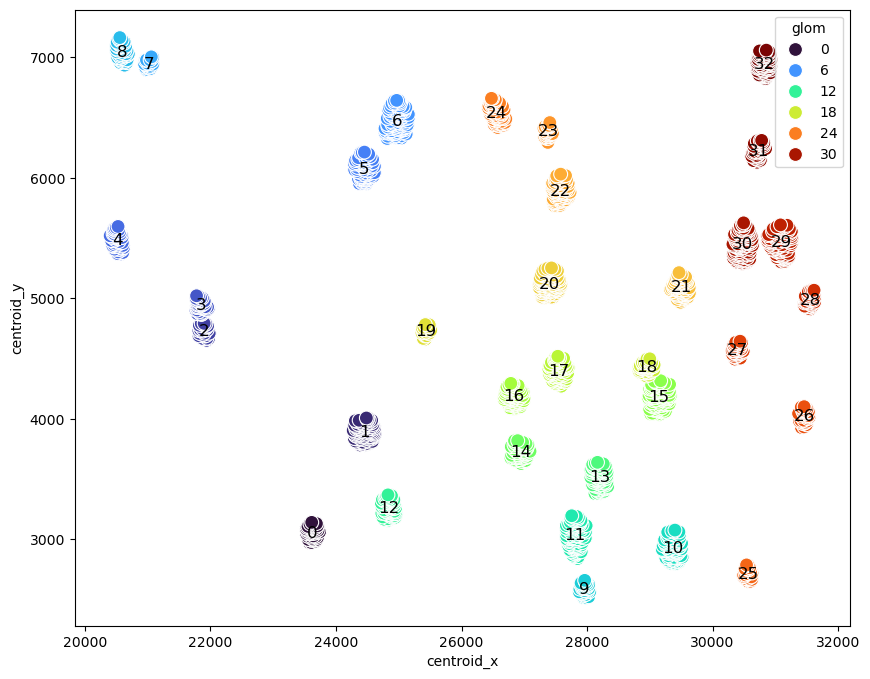

In [ ]:
plt.figure(figsize=(10, 8))

df_glom_idx = 0

data = df_glom_list[df_glom_idx][df_glom_list[df_glom_idx]['glom']>=0].copy()
sns.scatterplot(
    data=data, x='centroid_x', y='centroid_y', hue='glom', palette='turbo', s=100
)

cluster_centers = data.groupby('glom')[['centroid_x', 'centroid_y']].mean().reset_index()

for idx, row in cluster_centers.iterrows():
    plt.text(row['centroid_x'], row['centroid_y'], str(int(row['glom'])), fontsize=12, color='black', ha='center', va='center')

# plt.title('Glomeruli Distribution in Tissue S24-K2_273_3')

In [ ]:
filtered_df = new_plot_df[new_plot_df["glom"] >= 0]

# 3. Create the correlation matrix from the subset
corr_matrix = filtered_df[value_cols].corr()

In [ ]:
df.columns

Index(['tissue_id', 'group', 'unit', 'condition', 'mask_name', 'centroid_y',
       'centroid_x', 'CAR 18:0 (+H)', 'CAR 18:1 (+H)', 'CAR 18:2 (+H)',
       'CL 72:8 (-H)', 'CL 74:11 (-H)', 'Cer 17:2;2O/8:0;O (+Na)',
       'Collagen_Coherence', 'Collagen_Thickness',
       'HexCer 18:0;3O/23:0;(2OH) (-H)', 'LPC 16:0 (+H)', 'LPE 18:0 (-H)',
       'LPI 18:0 (-H)', 'Lipid_Unsaturation', 'Lipid_to_Protein',
       'PA 36:1 (-H)', 'PC 16:0_18:1 (+H)', 'PC 18:0_18:1 (+H)',
       'PC 18:0_20:4 (+H)', 'PC 32:0 (+H)', 'PC 34:2 (+H)', 'PC 35:4 (+H)',
       'PC 36:3 (+H)', 'PC 36:5 (+H)', 'PC 38:5 (+H)', 'PC 46:9 (-CH3)',
       'PC 48:9 (-CH3)', 'PC O-38:5 (+H)', 'PE 16:0_18:0 (-H)',
       'PE 16:0_18:2 (-H)', 'PE 16:0_20:4 (-H)', 'PE 16:0_22:6 (-H)',
       'PE 18:1_20:3 (-H)', 'PE 18:1_20:4 (-H)', 'PE 49:9 (-H)',
       'PG 18:1_22:6 (-H)', 'PI 16:0_18:0 (-H)', 'PI 16:0_20:4 (-H)',
       'PI 18:0_18:1 (-H)', 'PI 18:0_18:2 (-H)', 'PI 18:1_20:3 (-H)',
       'PI 34:1 (-H)', 'PS 16:0_20:4 (-

In [ ]:





# agg_df = filtered_df.groupby('glom')[subset_values].agg(['mean', 'std'])


In [ ]:
inner_cortex_data

CL 72:8 (-H)           CL 74:11 (-H)           SM 18:1;2O/16:0 (-CH3)  \
             mean       std          mean       std                   mean   
glom                                                                         
1.0     -0.924758  0.276863     -0.507045  0.281455                1.68495   

               SM 34:1;2O (+H)     SHexCer 42:1;3O (-H)            \
           std            mean std                 mean       std   
glom                                                                
1.0   0.707438             NaN NaN             -0.86511  0.055228   

     SHexCer 41:1;3O (-H)               Redox           Lipid_to_Protein  \
                     mean       std      mean       std             mean   
glom                                                                       
1.0             -0.759648  0.088689 -0.989917  0.543487         0.230895   

                
           std  
glom            
1.0   0.484383

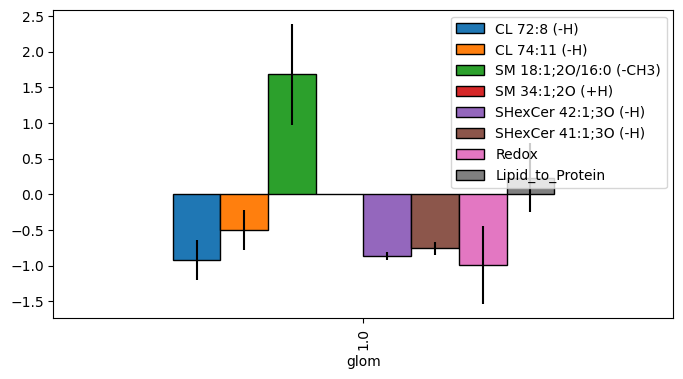

In [ ]:


plt.figure(figsize=(8,4))
inner_cortex_means.plot(
    kind='bar', 
    yerr=inner_cortex_stds,
    width=0.8, edgecolor='black', ax=plt.gca())
plt.show()

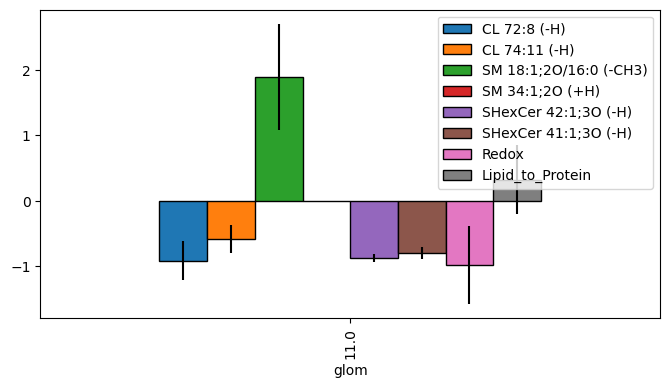

In [ ]:


plt.figure(figsize=(8,4))
outer_cortex_means.plot(
    kind='bar', 
    yerr=outer_cortex_stds,
    width=0.8, edgecolor='black', ax=plt.gca())
plt.show()

/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_46454/4155942040.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = glom_df.groupby('group')[subset_values].mean()
/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_46454/4155942040.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stds  = glom_df.groupby('group')[subset_values].std()


Saved: inner_cortex_gloms_inset.png


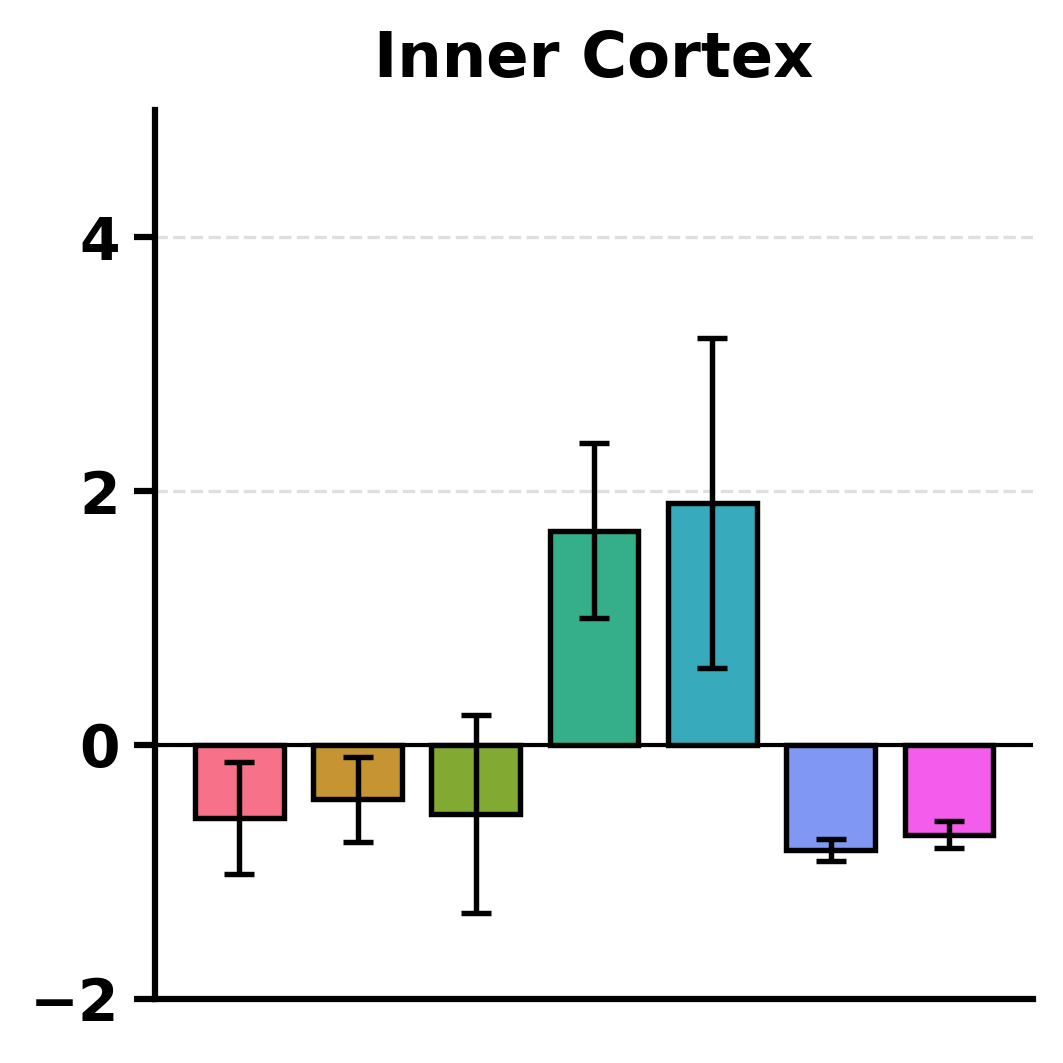

Saved: outer_cortex_gloms_inset.png


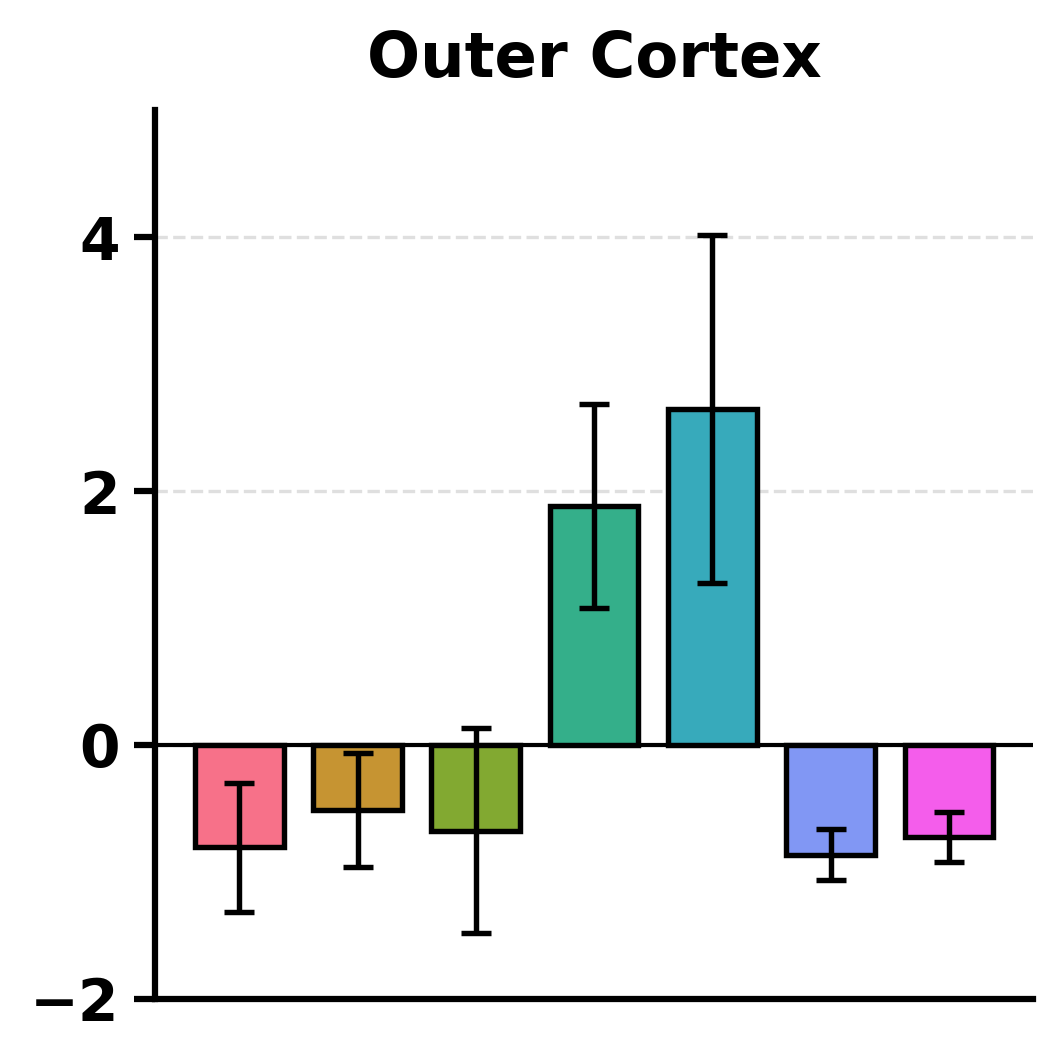

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# 1. DATA EXTRACTION
# -------------------------------------------------------------------------
subset_values = [
    'CL 72:8 (-H)', 
    'CL 74:11 (-H)',
    'Redox', 
    'SM 18:1;2O/16:0 (-CH3)',
    'PS 18:0_18:1 (-H)',
    'SHexCer 42:1;3O (-H)', 
    'SHexCer 42:2;3O (-H)', 
]

glom_df = filtered_df[filtered_df['mask_name'] == 'Cluster1']
means = glom_df.groupby('group')[subset_values].mean()
stds  = glom_df.groupby('group')[subset_values].std()

# Colors for the features
colors = sns.husl_palette(n_colors=len(subset_values))
x_pos = np.arange(len(subset_values))

# -------------------------------------------------------------------------
# 2. REUSABLE FUNCTION TO PLOT COMPACT JOURNAL INSET
# -------------------------------------------------------------------------
def plot_compact_glom_inset(group_name, save_filename=None):
    group_means = means.loc[group_name]
    group_stds  = stds.loc[group_name]

    # Compact square figure (ideal for insets & overlays)
    fig, ax = plt.subplots(figsize=(3.4, 3.4), dpi=300)

    # Plot bars with black edges and error bars
    bars = ax.bar(
        x_pos, 
        group_means, 
        yerr=group_stds,
        width=0.75, 
        color=colors, 
        edgecolor='black', 
        linewidth=1.3,
        capsize=3.5,
        error_kw=dict(lw=1.3, capthick=1.3, ecolor='black'),
        zorder=3
    )

    # Y-Limits & Baseline
    ax.set_ylim(-2, 5)
    ax.axhline(0, color='black', linewidth=1.0, zorder=2)
    ax.set_yticks([-2, 0, 2, 4])

    # Large, bold fonts for journal readability
    ax.tick_params(axis='y', which='major', labelsize=14, width=1.5, length=5, labelcolor='black')
    for tick in ax.get_yticklabels():
        tick.set_fontweight('bold')

    # Remove X-ticks and labels for compact inset
    ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)

    # Clean spines (keep left & bottom only, thick line for clarity)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(1.5)
        ax.spines[spine].set_color('black')

    # Subtle horizontal gridlines
    ax.grid(axis='y', linestyle='--', alpha=0.4, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

    # Header label badge (compact & high-contrast)
    ax.set_title(group_name, fontsize=15, fontweight='bold', pad=8, color='black')

    # Transparent background for seamless image overlay
    fig.patch.set_alpha(0.0)
    ax.patch.set_alpha(0.0)

    plt.tight_layout(pad=0.2)

    # Save high-res PNG with transparent background if requested
    if save_filename:
        plt.savefig(save_filename, dpi=300, transparent=True, bbox_inches='tight', pad_inches=0.02)
        print(f"Saved: {save_filename}")

    plt.show()

# -------------------------------------------------------------------------
# 3. GENERATE THE TWO INSET PLOTS
# -------------------------------------------------------------------------
plot_compact_glom_inset('Inner Cortex', save_filename='inner_cortex_gloms_inset.png')
plot_compact_glom_inset('Outer Cortex', save_filename='outer_cortex_gloms_inset.png')


/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_46454/4175359608.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = filtered_df[filtered_df['mask_name']=='Cluster1'].groupby('group')[subset_values].mean()
/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_46454/4175359608.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stds = filtered_df[filtered_df['mask_name']=='Cluster1'].groupby('group')[subset_values].std()


(-2.0, 5.0)

<Figure size 800x800 with 0 Axes>

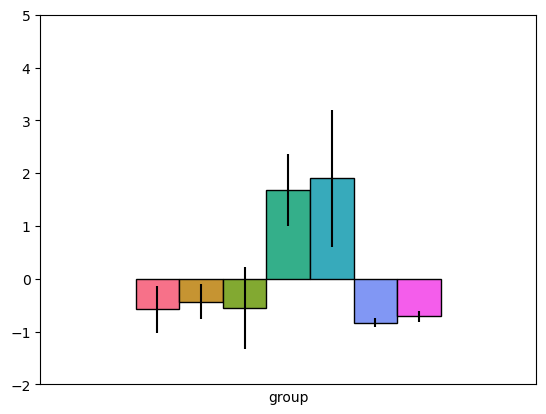

<Figure size 800x800 with 0 Axes>

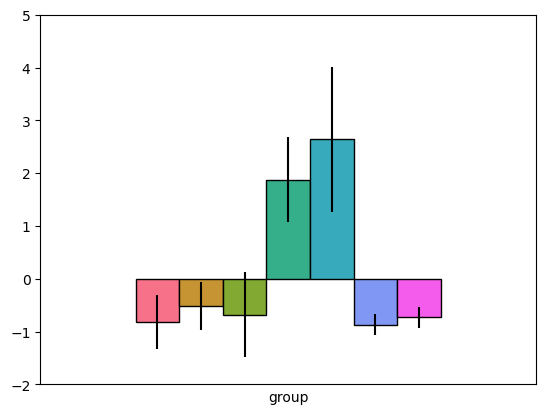

In [108]:
subset_values = [
    'CL 72:8 (-H)', 
    'CL 74:11 (-H)',
    'Redox', 
    'SM 18:1;2O/16:0 (-CH3)',
    'PS 18:0_18:1 (-H)',
    # 'SM 34:1;2O (+H)', 
    'SHexCer 42:1;3O (-H)', 
    'SHexCer 42:2;3O (-H)', 

    # 'Lipid_to_Protein'
    ]

means = filtered_df[filtered_df['mask_name']=='Cluster1'].groupby('group')[subset_values].mean()
stds = filtered_df[filtered_df['mask_name']=='Cluster1'].groupby('group')[subset_values].std()

inner_cortex_gloms = ['Inner Cortex']
inner_cortex_means = means.loc[inner_cortex_gloms]
inner_cortex_stds = stds.loc[inner_cortex_gloms]
outer_cortex_gloms = ['Outer Cortex']
outer_cortex_means = means.loc[outer_cortex_gloms]
outer_cortex_stds = stds.loc[outer_cortex_gloms]

# fig, axes = plt.subplots(1,2, figsize=(12,5), sharey=True)

colors = sns.husl_palette(n_colors = len(subset_values))

plt.figure(figsize=(8,8))
ax = inner_cortex_means.plot(
    kind='bar', 
    yerr=inner_cortex_stds,
    width=0.8, edgecolor='black',color=colors)
ax.tick_params(axis='x', which='both',bottom=False,top=False,labelbottom=False)
ax.legend().remove()

ax.set_ylim(-2, 5)
plt.figure(figsize=(8,8))
ax = outer_cortex_means.plot(
    kind='bar', 
    yerr=outer_cortex_stds,
    width=0.8, edgecolor='black', color=colors)
ax.tick_params(axis='x', which='both',bottom=False,top=False,labelbottom=False)
ax.legend().remove()
ax.set_ylim(-2, 5)

/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_46454/287382022.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = filtered_df[filtered_df['mask_name']=='Cluster1'].groupby('group')[subset_values].mean()
/var/folders/py/cw1d_lq902976sj5p0rf845m0000gn/T/ipykernel_46454/287382022.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stds = filtered_df[filtered_df['mask_name']=='Cluster1'].groupby('group')[subset_values].std()


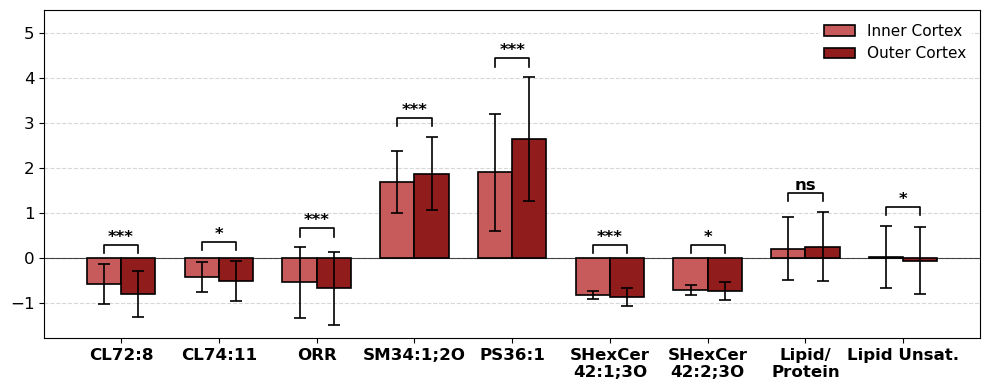

In [140]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

subset_values = [
    'CL 72:8 (-H)', 
    'CL 74:11 (-H)',
    'Redox', 
    'SM 18:1;2O/16:0 (-CH3)',
    'PS 18:0_18:1 (-H)',
    # 'SM 34:1;2O (+H)', 
    'SHexCer 42:1;3O (-H)', 
    'SHexCer 42:2;3O (-H)', 

    'Lipid_to_Protein',
    'Lipid_Unsaturation'
    ]

means = filtered_df[filtered_df['mask_name']=='Cluster1'].groupby('group')[subset_values].mean()
stds = filtered_df[filtered_df['mask_name']=='Cluster1'].groupby('group')[subset_values].std()

inner_cortex_gloms = ['Inner Cortex']
inner_cortex_means = means.loc[inner_cortex_gloms]
inner_cortex_stds = stds.loc[inner_cortex_gloms]
outer_cortex_gloms = ['Outer Cortex']
outer_cortex_means = means.loc[outer_cortex_gloms]
outer_cortex_stds = stds.loc[outer_cortex_gloms]

def to_series(obj, name=""):
    if isinstance(obj, pd.DataFrame):
        if obj.shape[0] == 1:
            return obj.iloc[0].rename(name)
        elif obj.shape[1] == 1:
            return obj.iloc[:, 0].rename(name)
        return obj.squeeze().rename(name)
    elif isinstance(obj, pd.Series):
        return obj.rename(name)
    elif isinstance(obj, dict):
        return pd.Series(obj, name=name)
    return pd.Series(obj, name=name)

# -------------------------------------------------------------------------
# 1. PREPARE MEANS, STDS & P-VALUES
# -------------------------------------------------------------------------
# Combine your group means and stds into aligned DataFrames
# (Columns = features/lipids/genes, Index = group names)
means_df = pd.DataFrame({
    'Inner Cortex': to_series(inner_cortex_means),
    'Outer Cortex': to_series(outer_cortex_means)
}).T  # Shape: (n_groups, n_features)
stds_df = pd.DataFrame({
    'Inner Cortex': to_series(inner_cortex_stds),
    'Outer Cortex': to_series(outer_cortex_stds)
}).T  # Shape: (n_groups, n_features)
# Option A: Provide p-values directly via a dictionary {feature_name: pval}
pval_dict = {
    'CL 72:8 (-H)': 0.0001, 
    'CL 74:11 (-H)':0.0209,
    'Redox': 0.00005, 
    'SM 18:1;2O/16:0 (-CH3)': 0.00028,
    'PS 18:0_18:1 (-H)': 0.00001,
    # 'SM 34:1;2O (+H)', 
    'SHexCer 42:1;3O (-H)': 0.000128, 
    'SHexCer 42:2;3O (-H)': 0.018, 
    'Lipid_to_Protein': 0.06,
    'Lipid_Unsaturation': 0.02 
}
# Option B: Or extract directly from your Games-Howell / ANOVA DataFrame
# pval_dict = gh_df.set_index('item')['pval'].to_dict()
# Example placeholder p-values (replace with your actual dictionary/csv)
# pval_dict = {col: 0.01 for col in means_df.columns}
# -------------------------------------------------------------------------
# 2. HELPER FOR SIGNIFICANCE STARS
# -------------------------------------------------------------------------
def get_stars(p):
    if p is None or pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"
# -------------------------------------------------------------------------
# 3. PLOT PAIRED BARS WITH ERROR BARS & SIGNIFICANCE
# -------------------------------------------------------------------------
features = list(means_df.columns)
groups = list(means_df.index)
n_features = len(features)
n_groups = len(groups)
# Colors for the groups (e.g. Set2, tab10, or custom hex codes)
colors = ['#c75b5b' , '#911c1c']  # [Group 1, Group 2]
fig, ax = plt.subplots(figsize=(max(10, 0.7 * n_features), 4))
x = np.arange(n_features)
total_width = 0.7
bar_width = total_width / n_groups
# Plot bars for each group
bar_containers = []
for i, group in enumerate(groups):
    offset = (i - (n_groups - 1) / 2) * bar_width
    bar = ax.bar(
        x + offset, 
        means_df.loc[group], 
        yerr=stds_df.loc[group],
        width=bar_width, 
        label=group, 
        color=colors[i % len(colors)],
        edgecolor='black', 
        linewidth=1.2,
        capsize=4, 
        error_kw=dict(lw=1.2, capthick=1.2),  # <-- Passed via error_kw
        zorder=3
    )
    bar_containers.append(bar)
# -------------------------------------------------------------------------
# 4. ADD SIGNIFICANCE BRACKETS / STARS
# -------------------------------------------------------------------------
y_min, y_max = ax.get_ylim()
y_span = y_max - y_min
bracket_h = 0.03 * y_span
for idx, feat in enumerate(features):
    pval = pval_dict.get(feat, None)
    star_str = get_stars(pval)
    
    if star_str != "":
        # Calculate maximum bar + yerr top across the paired groups
        top_y = max(
            means_df.loc[g, feat] + (stds_df.loc[g, feat] if pd.notna(stds_df.loc[g, feat]) else 0)
            for g in groups
        )

        # Position bracket above the highest error bar
        y_bracket = top_y + 0.04 * y_span
        if y_bracket + bracket_h < 0:
            y_bracket = 0.1

        x1 = idx - bar_width / 2
        x2 = idx + bar_width / 2
        
        # Draw bracket line
        ax.plot([x1, x1, x2, x2], 
                [y_bracket, y_bracket + bracket_h, y_bracket + bracket_h, y_bracket], 
                color='black', lw=1.2, zorder=4)
        
        # Draw stars / ns text
        ax.text((x1 + x2) / 2, y_bracket + bracket_h, star_str, 
                ha='center', va='bottom', fontsize=12, fontweight='bold', zorder=5)
# -------------------------------------------------------------------------
# 5. FORMATTING & AXES
# -------------------------------------------------------------------------
ax.set_xticks(x)

feature_names =[
    'CL72:8',
    'CL74:11',
    'ORR',
    'SM34:1;2O',
    'PS36:1',
    'SHexCer\n42:1;3O',
    'SHexCer\n42:2;3O',
    'Lipid/\nProtein',
    'Lipid Unsat.'
]

ax.set_xticklabels(feature_names, rotation=0, ha='center', rotation_mode='anchor', fontsize=12, fontweight='bold')
# ax.set_ylabel("Standardized Intensity / Mean", fontsize=16, fontweight='bold')
ax.tick_params(axis='y', which='major', labelsize=12)
# ax.set_yticklabels(rotation=0, fontsize=14, fontweight='bold')
# ax.set_title("Comparison Across Features", fontsize=15, fontweight='bold', pad=15)
# Grid & Layout
ax.grid(True, which='major', axis='y', linestyle='--', alpha=0.5, zorder=0)
ax.set_axisbelow(True)
ax.axhline(0, color='black', linewidth=0.8, linestyle='-', alpha=0.7)
# Adjust y limits to provide room for brackets
curr_ymin, curr_ymax = ax.get_ylim()
ax.set_ylim(curr_ymin, curr_ymax + 0.12 * (curr_ymax - curr_ymin))
ax.legend(frameon=True, facecolor='white', edgecolor='none', fontsize=11, loc='upper right')
plt.tight_layout()
plt.savefig(r"/Users/jorgevillazon/Library/CloudStorage/OneDrive-UCSanDiego/integrated_pipeline/final_plots/GLOM/glom_corr.png", transparent=True, dpi=300)
plt.show()


In [ ]:
filtered_

,CL 72:8 (-H),CL 74:11 (-H),Redox,SM 18:1;2O/16:0 (-CH3),PS 18:0_18:1 (-H),SHexCer 42:1;3O (-H),SHexCer 41:1;3O (-H),Lipid_to_Protein
group,,,,,,,,
Outer Cortex,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inner Cortex,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outer Stripe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inner Stripe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inner Medulla,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
plt.figure(figsize=(24, 24))
sns.heatmap(
    corr_matrix,
    annot=True,  # Displays the correlation values inside the boxes
    cmap="coolwarm",  # Color gradient from blue (negative) to red (positive)
    fmt=".2f",  # Formats the numbers to 2 decimal places
    vmin=-1,  # Sets the minimum value of the color bar to -1
    vmax=1,  # Sets the maximum value of the color bar to 1
    linewidths=0.5,  # Adds a small border between the boxes for readability
)

# 3. Add titles and labels for clarity
plt.title("Correlation Matrix Heatmap (Label > 0)", fontsize=14, pad=15)
plt.tight_layout()

# 4. Display the plot
plt.show()

NameError: name 'corr_matrix' is not defined

<Figure size 2400x2400 with 0 Axes>

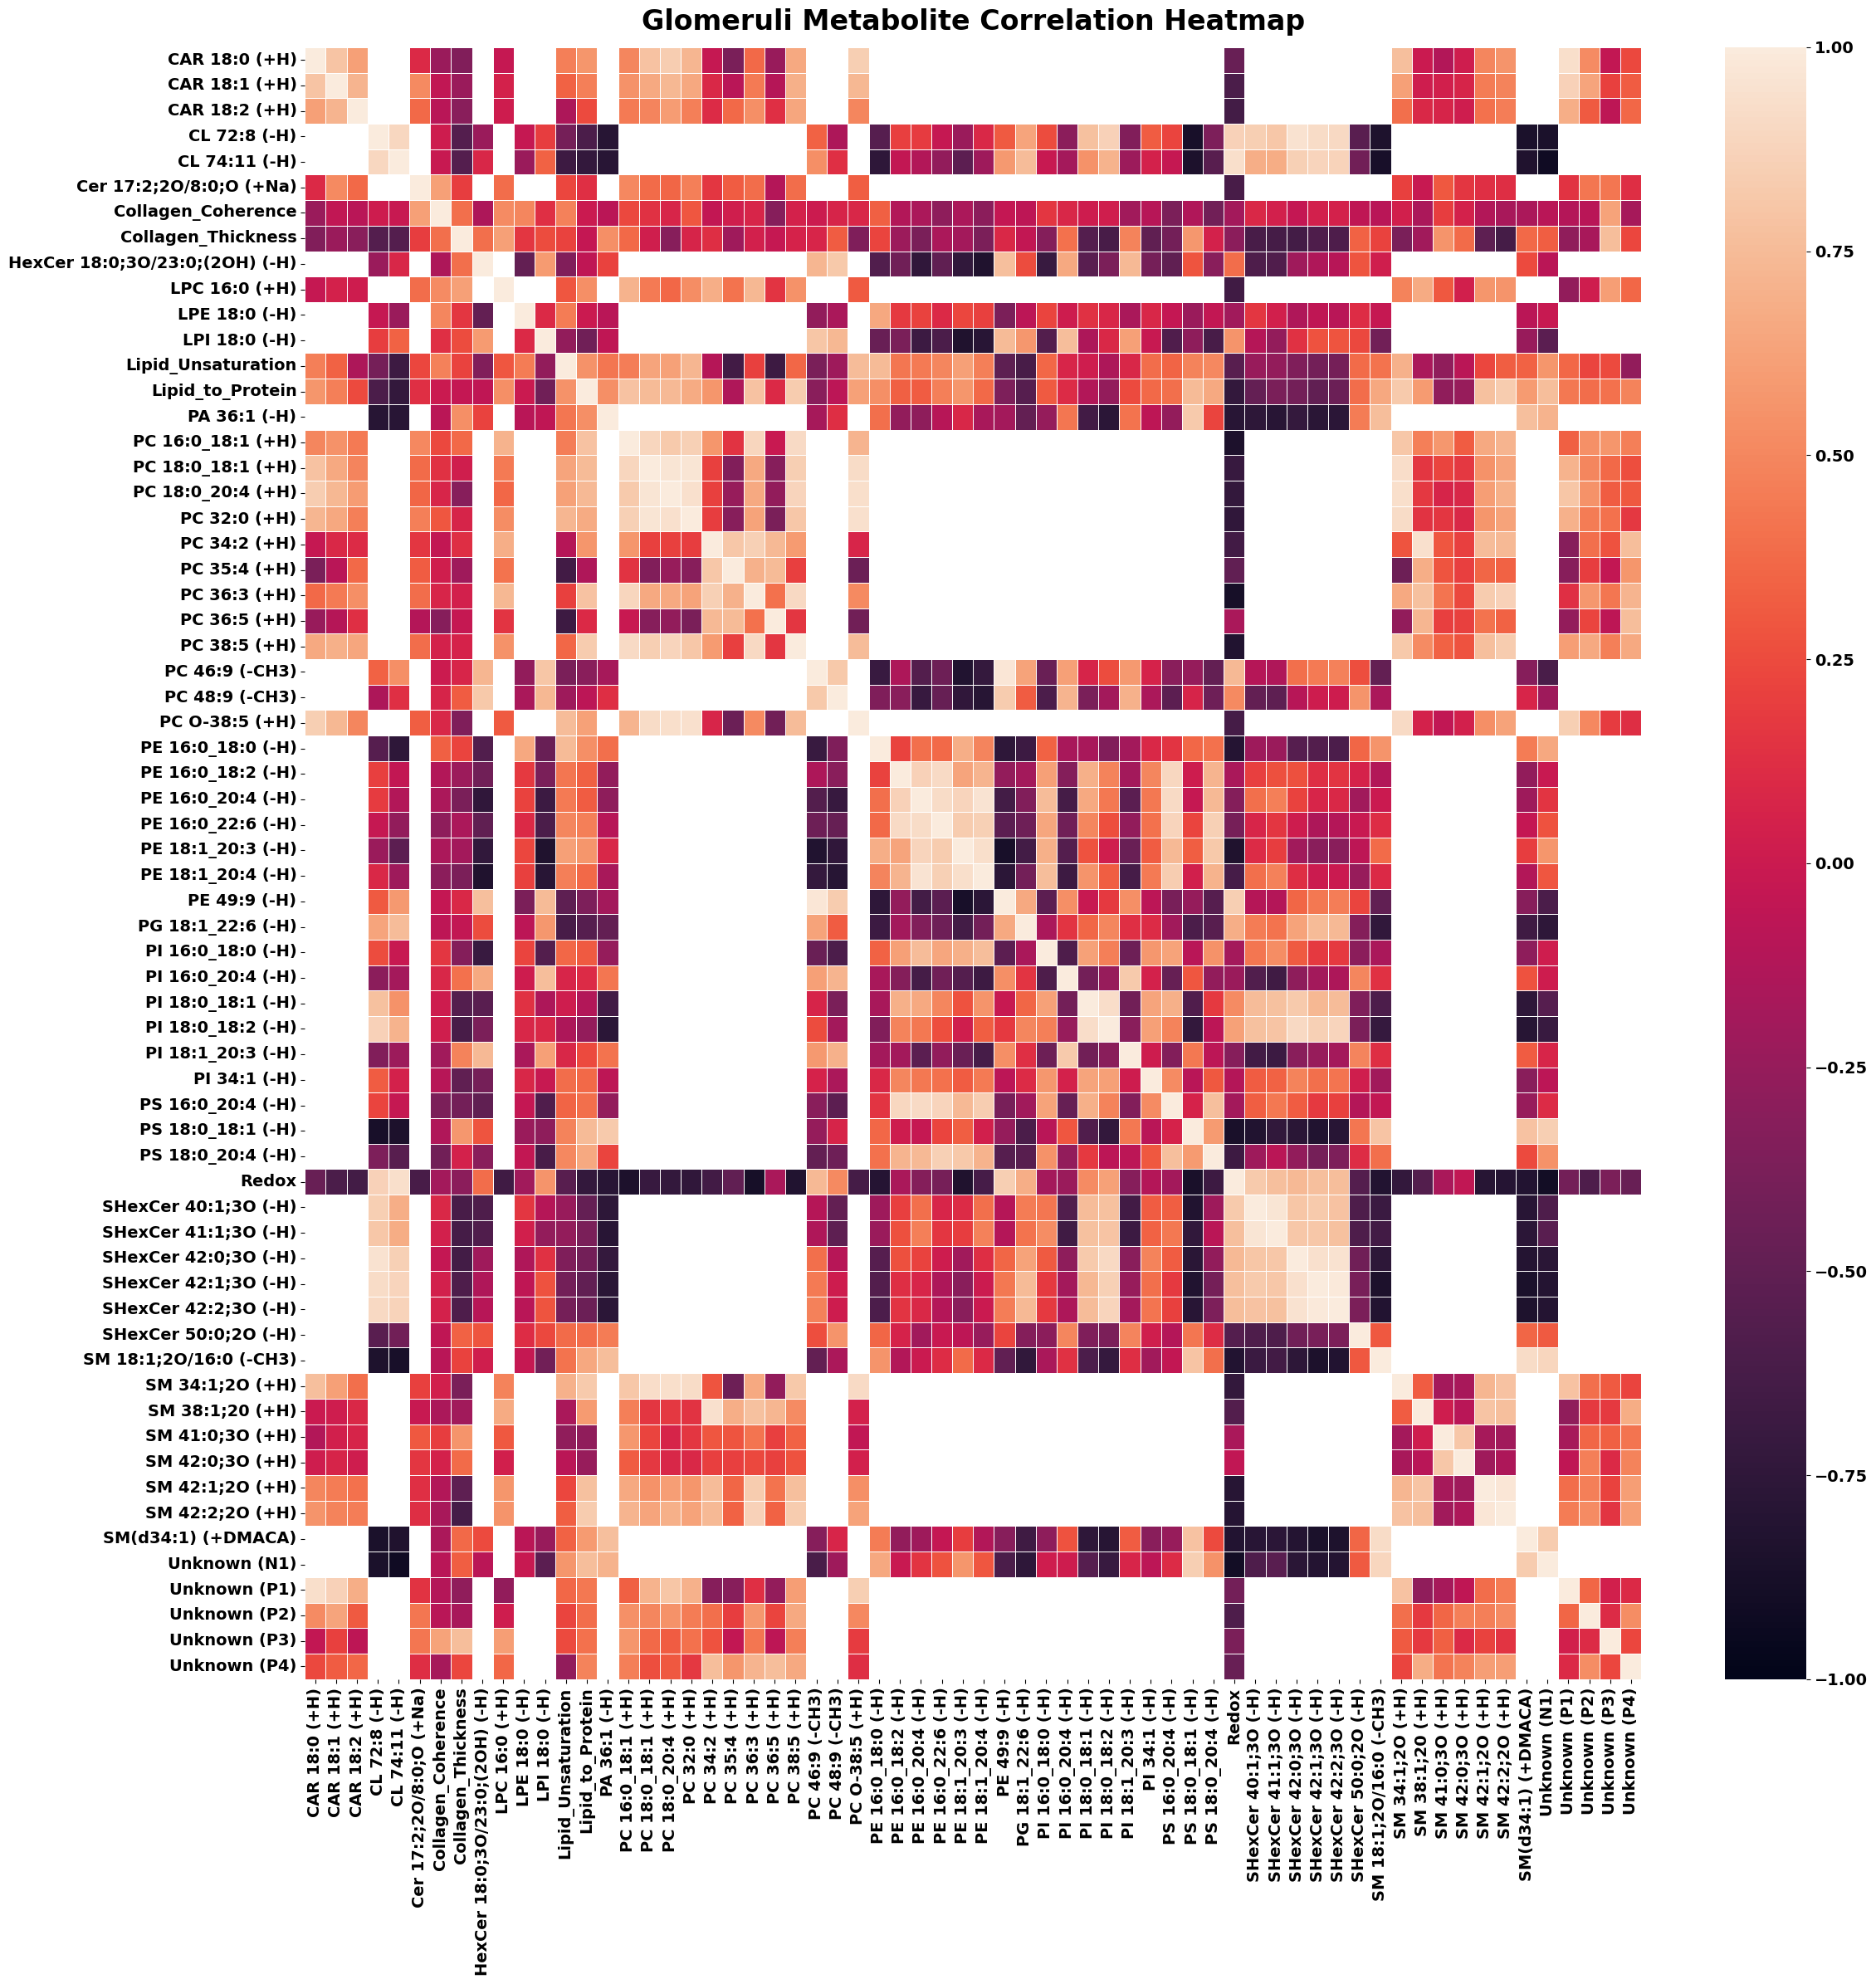

In [ ]:
group_averages = filtered_df.groupby("glom")[value_cols].mean()
avg_corr_matrix = group_averages.corr()
plt.figure(figsize=(24, 24))
ax = sns.heatmap(
    avg_corr_matrix,
    # annot=True,  # Displays the correlation values inside the boxes
    # cmap="coolwarm",  # Color gradient from blue (negative) to red (positive)
    # fmt=".2f",  # Formats the numbers to 2 decimal places
    vmin=-1,  # Sets the minimum value of the color bar to -1
    vmax=1,  # Sets the maximum value of the color bar to 1
    linewidths=0.5,  # Adds a small border between the boxes for readability
)
ax.tick_params(axis="both", which="major", labelsize=14, labelfontfamily="sans-serif")
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_weight("bold")

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14)
for label in cbar.ax.get_yticklabels():
    label.set_weight("bold")
# 3. Add titles and labels for clarity
plt.title("Glomeruli Metabolite Correlation Heatmap", fontsize=24, pad=15, fontweight='bold')
plt.tight_layout()

# 4. Display the plot


plt.savefig(r"/Users/jorgevillazon/Library/CloudStorage/OneDrive-UCSanDiego/integrated_pipeline/final_plots/GLOM/avg_corr_matrix.png", transparent=True, dpi=300)
plt.show()

In [ ]:
# 1. Mask the upper triangle and diagonal to avoid duplicate pairs and self-correlation
mask = np.triu(np.ones(avg_corr_matrix.shape), k=0).astype(bool)
unique_corr_matrix = avg_corr_matrix.where(~mask)

# 2. Unstack the matrix into a multi-index Series and reset the index to make it a DataFrame
flat_corr_df = unique_corr_matrix.unstack().reset_index()

# 3. Rename the columns to match your requested format
flat_corr_df.columns = ["Metabolite_1", "Metabolite_2", "Correlation"]

# 4. Drop the rows that were masked out (which are now NaN)
flat_corr_df = flat_corr_df.dropna().reset_index(drop=True)

# 5. Optional: Sort by strongest correlation (absolute value) for easier analysis
flat_corr_df["Abs_Corr"] = flat_corr_df["Correlation"].abs()
flat_corr_df = flat_corr_df.sort_values(by="Abs_Corr", ascending=False).drop(
    columns=["Abs_Corr"]
)

# 6. Export to a CSV file
flat_corr_df.to_csv(r"/Users/jorgevillazon/Library/CloudStorage/OneDrive-UCSanDiego/integrated_pipeline/final_plots/GLOM/group_average_correlations.csv", index=False)

In [ ]:
# group_summary = new_plot_df[new_plot_df['mask_name']=='Cluster1'].groupby(['tissue_id', 'glom'])[items_list].mean()
group_summary = fib_df[fib_df['unit']=="Interstitial cells | IGFBP7"].groupby(['group'])[items_list].mean()
corr_long = (
    group_summary.corr()
    .stack()
    .reset_index()
)
corr_long.columns = ['metric_1', 'metric_2', 'correlation']
corr_long = corr_long[corr_long['metric_1'] != corr_long['metric_2']]

# 3. Remove symmetric duplicate pairs (e.g., A-B vs B-A)
corr_long['pair'] = corr_long.apply(lambda row: tuple(sorted([row['metric_1'], row['metric_2']])), axis=1)
corr_long = corr_long.drop_duplicates(subset=['pair']).drop(columns=['pair'])
corr_long['abs_correlation'] = corr_long['correlation'].abs()
sorted_corr = corr_long.sort_values(by='abs_correlation', ascending=False)


In [ ]:
group_corr_long = (
    fib_df.groupby('group')[items_list]
    .corr()
    .stack()
    .reset_index()
    .rename(columns={'level_1': 'metric_1', 0: 'correlation'})
)
group_corr_long.columns = ['category', 'metric_1', 'metric_2', 'correlation']


In [ ]:
filter_corr = group_corr_long[group_corr_long['metric_1']!=group_corr_long['metric_2']]

a =filter_corr[filter_corr['metric_1']=='Collagen_Thickness'].sort_values(by='correlation',ascending=False)

In [ ]:
immune_units = [
# "Immune | CD20",
"Immune - MP | CD45, CD206",
"Immune - T | CD3, CD4",
"Immune - T | CD3, CD8",
]

other_units = [
    "Endothelium | CD31",
    "Endothelium | CD31, Podo",
    "Pericytes | CD90, CD31(-)",
    "VSMCs | aSMA",
    "Interstitial cells | IGFBP7"
]


In [ ]:

filtered_df = fib_df[fib_df['unit'].isin(other_units)]
filtered_df['unit'] = pd.Categorical(filtered_df['unit'], categories=other_units, ordered=True)
counts_df = filtered_df.groupby(['unit', 'group'])['Redox'].size().unstack(fill_value=0)
counts_df.plot(kind='bar', stacked=False, figsize=(10, 6))

plt.title('Distribution of Counts by Unit and Group')
plt.xlabel('Group')
plt.ylabel('Counts')
plt.legend(title='Column B')
plt.show()

In [ ]:
plt.figure(figsize=(18, 8))
# Seaborn handles the groupby and count behind the scenes
sns.countplot(data=filtered_df, x='unit', hue='group')

plt.title('Distribution of Counts')
plt.xlabel('Column A')
plt.ylabel('Count')
plt.show()

In [ ]:
plt.figure(figsize=(18, 8))
sns.barplot(
    data=filtered_df, 
    x='unit', 
    y='Collagen_Thickness', 
    hue='group', 
    errorbar='se'  
)

plt.title('Mean and Standard Error Distribution')
plt.xlabel('Column A')
plt.ylabel('Mean of Numeric Column')
plt.legend(title='Column B')
plt.show()

In [ ]:

filtered_df = fib_df[fib_df['unit'].isin(other_units)]
filtered_df['unit'] = pd.Categorical(filtered_df['unit'], categories=other_units, ordered=True)
# 1. Reshape data from 'wide' to 'long' format
# 'id_vars' are your grouping columns; 'value_vars' are the numeric columns to plot
df_long = filtered_df.melt(
    id_vars=['unit', 'group'], 
    value_vars=['Collagen_Thickness', 'Collagen_Coherence', 'CL 72:8 (-H)', 'CL 74:11 (-H)'
    , 'Redox', 'Lipid Unsat.', 'Lipid/Protein'],
    var_name='Metric', 
    value_name='Value'
)

y_col = 'group'
hue_col = 'unit'

# 2. Plot using catplot
# col='Metric' tells Seaborn to create a unique subplot for each column in value_vars
n_colors = filtered_df[hue_col].unique()
colors = sns.color_palette("husl", len(n_colors))

# Map category name -> unique color
palette_dict = dict(zip(n_colors, colors))

g = sns.catplot(
    data=df_long,
    kind='bar',
    x='Value',
    y=y_col,
    hue=hue_col,
    palette=palette_dict,
    sharey=True,
    col='Metric',
    errorbar='se',       # Change to 'sd' for Standard Deviation
    capsize=0.1,         # Adds horizontal caps to the error bars
    col_wrap=3,          # Wraps to a new row after 3 columns
    height=10,
    aspect=0.6
)
for ax in g.axes.flatten():
  # Get the numeric positions of the categorical ticks (e.g., [0, 1, 2, 3])
  yticks = ax.get_yticks()

  # Draw a vertical line exactly halfway between each consecutive category
  for i in range(len(yticks) - 1):
    midpoint = (yticks[i] + yticks[i + 1]) / 2
    ax.axhline(
        y=midpoint,
        color="lightgrey",
        linestyle="--",
        linewidth=1.2,
        zorder=0,  # Keeps lines behind the bars/plots
    )
# 3. Clean up titles and labels
g.set_titles("{col_name}")
g.set_axis_labels("Column A", "Mean Value")
plt.show()

In [ ]:
filtered_df = fib_df[fib_df['unit'].isin(immune_units)]
filtered_df['unit'] = pd.Categorical(filtered_df['unit'], categories=immune_units, ordered=True)

# 1. Reshape data from 'wide' to 'long' format
# 'id_vars' are your grouping columns; 'value_vars' are the numeric columns to plot
df_long = filtered_df.melt(
    id_vars=['unit', 'group'], 
    value_vars=['Redox', 'CL'],
    var_name='Metric', 
    value_name='Value'
)

# 2. Plot using catplot
# col='Metric' tells Seaborn to create a unique subplot for each column in value_vars
n_colors = filtered_df["unit"].unique()
colors = sns.color_palette("husl", len(n_colors))

# Map category name -> unique color
palette_dict = dict(zip(n_colors, colors))

g = sns.catplot(
    data=df_long,
    kind='bar',
    x='Value',
    y='group',
    hue='unit',
    palette=palette_dict,
    sharey=True,
    col='Metric',
    errorbar='se',       # Change to 'sd' for Standard Deviation
    capsize=0.1,         # Adds horizontal caps to the error bars
    col_wrap=3,          # Wraps to a new row after 3 columns
    height=10,
    aspect=0.6
)
for ax in g.axes.flatten():
  # Get the numeric positions of the categorical ticks (e.g., [0, 1, 2, 3])
  yticks = ax.get_yticks()

  # Draw a vertical line exactly halfway between each consecutive category
  for i in range(len(yticks) - 1):
    midpoint = (yticks[i] + yticks[i + 1]) / 2
    ax.axhline(
        y=midpoint,
        color="lightgrey",
        linestyle="--",
        linewidth=1.2,
        zorder=0,  # Keeps lines behind the bars/plots
    )
# 3. Clean up titles and labels
g.set_titles("{col_name}")
g.set_axis_labels("Column A", "Mean Value")
plt.show()

In [ ]:
# import umap 

# from sklearn.preprocessing import StandardScaler
# scaler = StandardScaler().set_output(transform="pandas")
# umap_df = df.copy()
# umap_df[df.columns[7:-13]] = scaler.fit_transform(df[df.columns[7:-13]])
# # umap_df = umap_df.dropna()
# reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
# embedding = reducer.fit_transform(umap_df[df.columns[7:-13]])

# umap_df['umap_1'] = embedding[:, 0]
# umap_df['umap_2'] = embedding[:, 1]
        

In [ ]:
# import umap 
# umap_df = df.copy()

# # feature_cols = df.columns[7:-13]

# # q1 = df.groupby('mask_name')[feature_cols].transform('quantile', 0.25)
# # q3 = df.groupby('mask_name')[feature_cols].transform('quantile', 0.75)
# # iqr = q3 - q1

# # # 2. Define outlier boundaries (1.5 * IQR rule)
# # lower_bound = q1 - 1.5 * iqr
# # upper_bound = q3 + 1.5 * iqr

# # # 3. Create a mask where rows must be within bounds for ALL features
# # # True if feature is within group bounds, False if it is an outlier
# # within_bounds = (df[feature_cols] >= lower_bound) & (df[feature_cols] <= upper_bound)

# # # Keep rows where NO feature is an outlier
# # clean_df = df[within_bounds.all(axis=1)].copy()

# # # 4. Separate features and scale/run UMAP on the cleaned data
# # umap_df = clean_df


# umap_df[df.columns[7:-13]] = umap_df.groupby('tissue_id')[df.columns[7:-13]].transform(lambda x: (x - x.mean()) / x.std())
# # umap_df = umap_df.dropna()
# reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
# embedding = reducer.fit_transform(umap_df[df.columns[7:-13]])

umap_df['umap_1'] = embedding[:, 0]
umap_df['umap_2'] = embedding[:, 1]

In [ ]:
umap_df = pd.read_csv(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv-test\umap-nomid-output.csv")


In [ ]:
umap_df2 = umap_df.replace({'Middle Cortex': 'Outer Cortex', 'Juxtamedullary Cortex': 'Inner Cortex'} )

In [ ]:
import matplotlib.patheffects as pe
import numpy as np
fig, ax = plt.subplots(figsize=(12, 12))


"""Keep this cell to load and remap saved umap csv for plotting"""
# umap_df = pd.read_csv(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv-test\umap-nomid-output.csv")
# # umap_df = df.copy()
# umap_df2 = umap_df.replace({'Middle Cortex': 'Outer Cortex', 'Juxtamedullary Cortex': 'Inner Cortex', 'Cluster3':'Cluster4', 'Cluster13': 'Cluster12', 'Cluster14': 'Cluster12', 'Cluster10': 'Cluster9'} )
hue_colors={
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    # "Cluster3": "#42a84c",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster8": "#840a62", 
    "Cluster9": "#f47ad2",
    # "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster12": "#09234b",
    # "Cluster13": "#0a3b84",
    # "Cluster14": "#355483",
    "Cluster15": "#105ac9",
    "Cluster16": "#357fee",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster22": "#ffede4",
    "Cluster23": "#8b3103",
    "Cluster24": "#f85706",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }


umap_df = umap_df2.sample(frac=1, random_state=42)
sns.scatterplot(
    data=umap_df,
    x='umap_1', y='umap_2',
    hue='mask_name',
    palette=hue_colors,
    # hue_order=hue_order_display,
    alpha=0.9,
    edgecolor='w',
    linewidth=0.2,
    s=5,
    ax=ax
)
embeddings = umap_df[["umap_1", "umap_2"]].values
labels = umap_df["group"].values
unique_labels = umap_df["group"].unique()

# 5. Place clean, bold labels at each cluster's median centroid
# for label in unique_labels:
#     mask = labels == label
#     # Using median for both coordinates yields a better geometric center
#     centroid_x = np.median(embeddings[mask, 0])
#     centroid_y = np.median(embeddings[mask, 1])

#     ax.text(
#         centroid_x,
#         centroid_y,
#         label,
#         fontsize=12,  # Adjusted to fit 6x6 figure nicely
#         fontweight="bold",
#         ha="center",
#         va="center",
#         color="black",
#         rotation=90,
#         path_effects=[pe.withStroke(linewidth=3, foreground="white")],
#         zorder=100,
#     )
# Formatting axes
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([])
ax.set_yticklabels([])
sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
ax.tick_params(left=False, bottom=False)

# Remove the default legend (since we have text labels on centroids)
legend = ax.get_legend()
# if legend is not None:
#     legend.remove()
# plt.savefig(os.path.join(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\plots_CODEX_clusters-regions_masks", "lipids-nomid-UMAP.png"), dpi=300, transparent=True)

In [ ]:
leg = plt.legend
fill_colors = [handle.get_facecolor()[0] for handle in leg.legendHandles]

In [ ]:
umap_df2.to_csv(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv-test\umap-nomid-output.csv", index=False)

## Region Gradients

In [ ]:
import numpy as np
df = df.replace({'Middle Cortex': 'Outer Cortex', 'Juxtamedullary Cortex': 'Inner Cortex', 'Cluster3':'Cluster4', 'Cluster13': 'Cluster12', 'Cluster14': 'Cluster12', 'Cluster10': 'Cluster9'} )

group_order = ['Outer Cortex', 'Inner Cortex', 'Outer Stripe', 'Inner Stripe', 'Inner Medulla']

regions = ['Outer\nCortex', 'Inner\nCortex', 'Outer\nStripe', 'Inner\nStripe', 'Inner\nMedulla']

unit_order = [
    "Cluster1",
    "Cluster2",
    #   "Cluster3",
    "Cluster4",
    "Cluster5",
    "Cluster6",
    "Cluster7",
    "Cluster8",
    "Cluster9",
    #   "Cluster10",
    "Cluster11",
    "Cluster12",
    #   "Cluster13",
    #   "Cluster14",
    "Cluster15",
    "Cluster16",
    "Cluster17",
    "Cluster18",
    "Cluster19",
    "Cluster20",
    "Cluster21",
    "Cluster22",
    "Cluster23",
    "Cluster24",
    "Cluster25",
    "Cluster26"
    ]
df['mask_name'] = pd.Categorical(df['mask_name'], categories=unit_order, ordered=True)
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

hue_colors={
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    # "Cluster3": "#42a84c",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster8": "#840a62", 
    "Cluster9": "#f47ad2",
    # "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster12": "#09234b",
    # "Cluster13": "#0a3b84",
    # "Cluster14": "#355483",
    "Cluster15": "#105ac9",
    "Cluster16": "#357fee",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster22": "#ffede4",
    "Cluster23": "#8b3103",
    "Cluster24": "#f85706",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }

fig, ax = plt.subplots(figsize=(2.25*len(col_groups.keys()), 6), ncols=len(col_groups.keys()), nrows=1, sharey=True)

# regions = ['Outer\nCortex', 'Inner\nCortex', 'CM\nBoundary', 'Outer\nStripe', 'Inner\nStripe']
for i, val_col in enumerate(col_groups.keys()):
    item_data_plot = df[['mask_name', 'group', val_col]].replace([np.inf, -np.inf], np.nan).dropna(subset=[val_col]).copy()
    agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])[val_col].agg(['mean', 'count']).reset_index()
    agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')
    agg_data_plot = agg_data_plot[agg_data_plot['count'] / agg_data_plot['unit_total'] >=0.07]
    pivot_df = agg_data_plot.pivot(index='group', columns='mask_name', values='mean')

    z_df = pivot_df.copy().astype(float)
    z_values = z_df.to_numpy(dtype=float)
    z_mean = np.nanmean(z_values)
    z_std = np.nanstd(z_values)
    if np.isnan(z_std) or z_std == 0:
        z_df = z_df - z_mean
    else:
        z_df = (z_df - z_mean) / z_std

    item_abs_max = np.nanmax(np.abs(z_df.to_numpy(dtype=float)))
    if np.isnan(item_abs_max):
        item_abs_max = 0

    inverted_df = z_df.iloc[::-1, ::-1]
    inverted_df.plot(ax=ax[i], kind='barh', xlabel=val_col, width=0.9, color=list(hue_colors.values())[::-1]) 
    # ax[i].set_yticklabels(group_order[::-1],fontsize=14, fontweight='bold')


    ax[i].axvline(0, color='lightgray', linestyle='--')
    ax[i].get_legend().remove() 


    y_ticks = ax[i].get_yticks()

    if i == 0:
        sns.despine(ax=ax[i], top=True, right=True, left=False)
    elif i == len(col_groups.keys()):
        sns.despine(ax=ax[i], top=True, right=False, left=True)
    else:
        sns.despine(ax=ax[i], top=True, right=True, left=True)

    if len(y_ticks) > 1:
        # Calculate the distance between bars
        spacing = y_ticks[1] - y_ticks[0]
        
        # This includes boundary lines below the first bar and above the last bar
        minor_ticks = np.arange(y_ticks[0] - spacing/2, y_ticks[-1] + spacing, spacing)
        ax[i].set_yticks(minor_ticks, minor=True)
        
        # Turn off the major grid (at the ticks) and turn on the minor grid
        ax[i].grid(False, which='major', axis='y')
        ax[i].grid(True, which='minor', axis='y', linestyle='-.', color='gray', linewidth=0.9)
        
    # ax[i].set_xlim(-2, 2)


    ax[i].tick_params(which='both', axis='y', length=0)
    ax[i].tick_params(axis='x', labelsize=14)
    ax[i].set_yticklabels(regions[::-1], fontsize=20, fontweight='bold')
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_title(val_col.replace(" ",'\n'), y=1.04, va='center', fontsize=18, fontweight='bold')

    # ax[i].xaxis.label.set(fontsize=18, fontweight='bold')
plt.tight_layout()
# plt.savefig(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\plots_CODEX_clusters-regions_masks\region_gradient_barplot.png",dpi=300, transparent=True)
plt.show()

In [ ]:
df2 = df.copy()
condition_tdl = (df['mask_name'].isin(['Cluster6', 'Cluster7']) & df['group'].isin(['Outer Cortex', 'Inner Cortex']))
df2.loc[condition_tdl, 'group'] = 'Outer Stripe'

condition_pt = (df['mask_name'].isin(['Cluster2', 'Cluster4', 'Cluster5']) & df['group'].isin(['Inner Stripe']))
df2.loc[condition_pt, 'group'] = 'Outer Stripe'

condition_tal = (df['mask_name'].isin(['Cluster8', 'Cluster9']) & df['group'].isin(['Inner Medulla']))
df2.loc[condition_tal, 'group'] = 'Inner Stripe'

condition_glom = (df['mask_name'].isin(['Cluster1']) & df['group'].isin(['Outer Stripe']))
df2.loc[condition_glom, 'group'] = 'Inner Cortex'

In [ ]:
df2.groupby(['group', 'mask_name'])['CL'].agg(['mean', 'count']).reset_index().pivot(index='group', columns='mask_name', values='count')



In [ ]:
import numpy as np
df['mask_name'] = pd.Categorical(df['mask_name'], categories=unit_order, ordered=True)
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

item_data_plot = df[['mask_name', 'group', 'Lipid Unsat.']].replace([np.inf, -np.inf], np.nan).dropna(subset=['Lipid Unsat.']).copy()
agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])['Lipid Unsat.'].agg(['mean', 'count']).reset_index()
agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')
agg_data_plot = agg_data_plot[agg_data_plot['count'] / agg_data_plot['unit_total'] >=0.07]
pivot_df = agg_data_plot.pivot(index='group', columns='mask_name', values='mean')


In [ ]:

pivot_df.plot(kind='bar', xlabel=val_col, width=0.9) 
legend = plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')

In [ ]:
df = df[(df.groupby(['mask_name', 'group'])['mask_name'].transform('size') / df.groupby('mask_name')['mask_name'].transform('size')) * 100 >= 10]

In [ ]:
df.groupby(['mask_name', 'group'])['mask_name'].agg(['count'])

In [ ]:
import sys 
from pathlib import Path
sys.path.insert(0, os.path.abspath('..'))
from core.hsi_visualizer import HSI_Visualizer

workspace_dir = str(Path.cwd().parent)
wn_1 =2700
wn_2 = 3100
num_samp = 61

visualizer = HSI_Visualizer(
    mol_path=os.path.join(workspace_dir, 'molecule_dataset', 'lipid_subtype_wn_61_test.npz'),
    wavenumber_start=wn_1, wavenumber_end=wn_2, num_samples=num_samp
)

In [ ]:
group_order = ['Outer Cortex', 'Inner Cortex', 'Outer Stripe', 'Inner Stripe', 'Inner Medulla']
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

df.rename(columns={'mask_name':'Unit', 'group': 'Group_ID'}, inplace=True)

items_list = list(df.columns[7:])
output_dir = os.path.join(workspace_dir, 'plots', 'inter_group_unit_boxplots')

unit_colors= {
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    "Cluster3": "#10c922",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster8": "#840a62",
    "Cluster9": "#f47ad2",
    "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster12": "#0a3b84",
    "Cluster13": "#0e52b7",
    "Cluster14": "#0e52b7",
    "Cluster15": "#1369eb",
    "Cluster16": "#478af0",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster22": "#8b3103",
    "Cluster23": "#d44a05",
    "Cluster24": "#f9702a",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }
display_units_boxplots = [
    "Cluster2",
    "Cluster4",
    "Cluster5",
]

unit_display_names = {
    "Cluster1": "Glomeruli | Podo, CD31",
    "Cluster2": "PT | LRP2",
    "Cluster3": "PT | LRP2, AQP1, CD90",
    "Cluster4": "PT | THY1",
    "Cluster5": "PT | PROM1/VCAM1",
    "Cluster6": "TDL | AQP1, Cyto8 (N1)",
    "Cluster7": "TDL | AQP1, Cyto8 (N2)",
    "Cluster8": "TAL | NaK/UMOD",
    "Cluster9": "TAL | UMOD",
    "Cluster10": "TAL | UMOD",
    "Cluster11": "DCT | SLC12a3",
    "Cluster12": "DN | Cyto8 (N1)",
    "Cluster13": "DN | Cyto8",
    "Cluster14": "DN | Cyto8 (N3)",
    "Cluster15": "DN | Cyto8, Bcat",
    "Cluster16": "DN | Cyto8, Bcat, Ecad",
    "Cluster17": "DN | Cyto8, Ecad",
    "Cluster18": "Endothelium | CD31",
    "Cluster19": "Endothelium | CD31, Podo",
    "Cluster20": "Pericytes | CD90, CD31(-)",
    "Cluster21": "VSMCs | aSMA",
    "Cluster22": "Immune | CD20",
    "Cluster23": "Immune - MP | CD45, CD206",
    "Cluster24": "Immune - T | CD3, CD4",
    "Cluster25": "Immune - T | CD3, CD8",
    "Cluster26": "Interstitial cells | IGFBP7"
  }


visualizer.create_individual_barplots(
    df=df, 
    value_col=None,        # Not needed for wide format
    grouping_col=None,     # Signal that we are using Wide format
    items_list=items_list, # The column names
    output_dir=output_dir,
    data_type='Ratio',
    units_to_display=display_units_boxplots,
    consolidate_Group_IDs=True,
    plot_type='violin',
    sig_style='stars_only' if len(display_units_boxplots) > 6 else 'brackets',
    show_plots=False,
    display_name_map=unit_display_names,
    unit_color_map=unit_colors,
    unit_display_map=unit_display_names,
    subgroup_list = group_order,
    remove_outliers=True,
    show_scatter=True,
    show_empty_subgroups=True,
    orientation='vertical'
)

In [ ]:
filtered_df = df[(df.groupby(['mask_name', 'group'])['mask_name'].transform('size') / df.groupby('mask_name')['mask_name'].transform('size')) * 100 >= 70]

In [ ]:
group_order = ['Outer Cortex', 'Inner Cortex', 'Outer Stripe', 'Inner Stripe', 'Inner Medulla']

In [ ]:

df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

In [ ]:
df['group'].unique()